In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Середовище підготовлено до роботи")

Середовище підготовлено до роботи


In [2]:
iris = load_iris()

flowers = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

flowers["species"] = [
    iris.target_names[number]
    for number in iris.target
]

print("Перші записи набору даних:")
display(flowers.head(8))

print("\nКількість квітів кожного виду:")
print(flowers["species"].value_counts())

Перші записи набору даних:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa



Кількість квітів кожного виду:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
features = iris.data
labels = iris.target

train_features, test_features, train_labels, test_labels = train_test_split(
    features,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print(f"Для навчання використано: {train_features.shape[0]} записів")
print(f"Для тестування використано: {test_features.shape[0]} записів")
print(f"Кількість характеристик: {train_features.shape[1]}")

Для навчання використано: 120 записів
Для тестування використано: 30 записів
Кількість характеристик: 4


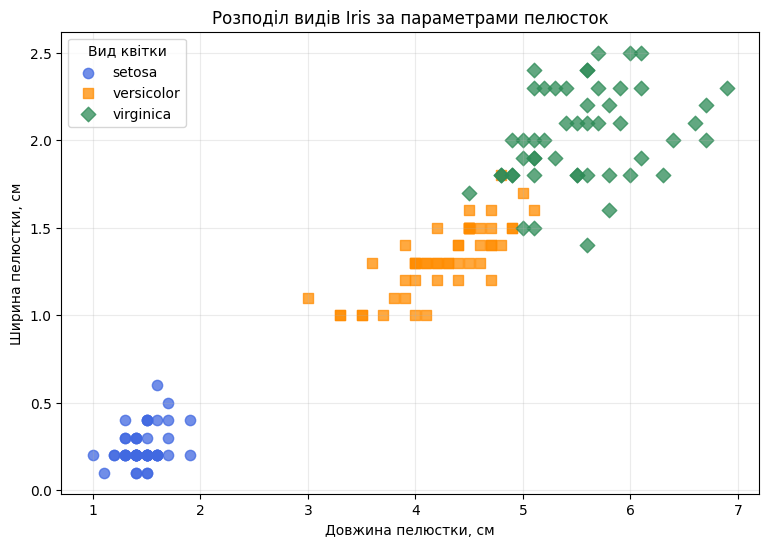

In [4]:
colors = ["royalblue", "darkorange", "seagreen"]
markers = ["o", "s", "D"]

plt.figure(figsize=(9, 6))

for class_id, class_name in enumerate(iris.target_names):
    selected = labels == class_id

    plt.scatter(
        features[selected, 2],
        features[selected, 3],
        color=colors[class_id],
        marker=markers[class_id],
        s=55,
        alpha=0.75,
        label=class_name
    )

plt.title("Розподіл видів Iris за параметрами пелюсток")
plt.xlabel("Довжина пелюстки, см")
plt.ylabel("Ширина пелюстки, см")
plt.grid(alpha=0.25)
plt.legend(title="Вид квітки")
plt.show()

In [5]:
classification_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

classification_model.fit(
    train_features,
    train_labels
)

print("Стандартизацію даних виконано")
print("Модель KNN із п’ятьма сусідами навчена")

Стандартизацію даних виконано
Модель KNN із п’ятьма сусідами навчена


In [6]:
unknown_flower = np.array([
    [6.8, 3.0, 5.5, 2.1]
])

predicted_id = classification_model.predict(unknown_flower)[0]
predicted_species = iris.target_names[predicted_id]

print("Параметри досліджуваної квітки:")
print("Довжина чашолистка:", unknown_flower[0, 0], "см")
print("Ширина чашолистка:", unknown_flower[0, 1], "см")
print("Довжина пелюстки:", unknown_flower[0, 2], "см")
print("Ширина пелюстки:", unknown_flower[0, 3], "см")
print("\nВизначений вид:", predicted_species)

Параметри досліджуваної квітки:
Довжина чашолистка: 6.8 см
Ширина чашолистка: 3.0 см
Довжина пелюстки: 5.5 см
Ширина пелюстки: 2.1 см

Визначений вид: virginica


In [7]:
predicted_labels = classification_model.predict(test_features)
accuracy = accuracy_score(test_labels, predicted_labels)

successful = np.count_nonzero(predicted_labels == test_labels)
failed = test_labels.size - successful

print(f"Правильних прогнозів: {successful} із {test_labels.size}")
print(f"Помилкових прогнозів: {failed}")
print(f"Загальна точність моделі: {accuracy:.4f}")
print(f"Точність у відсотках: {accuracy * 100:.2f}%")

Правильних прогнозів: 28 із 30
Помилкових прогнозів: 2
Загальна точність моделі: 0.9333
Точність у відсотках: 93.33%


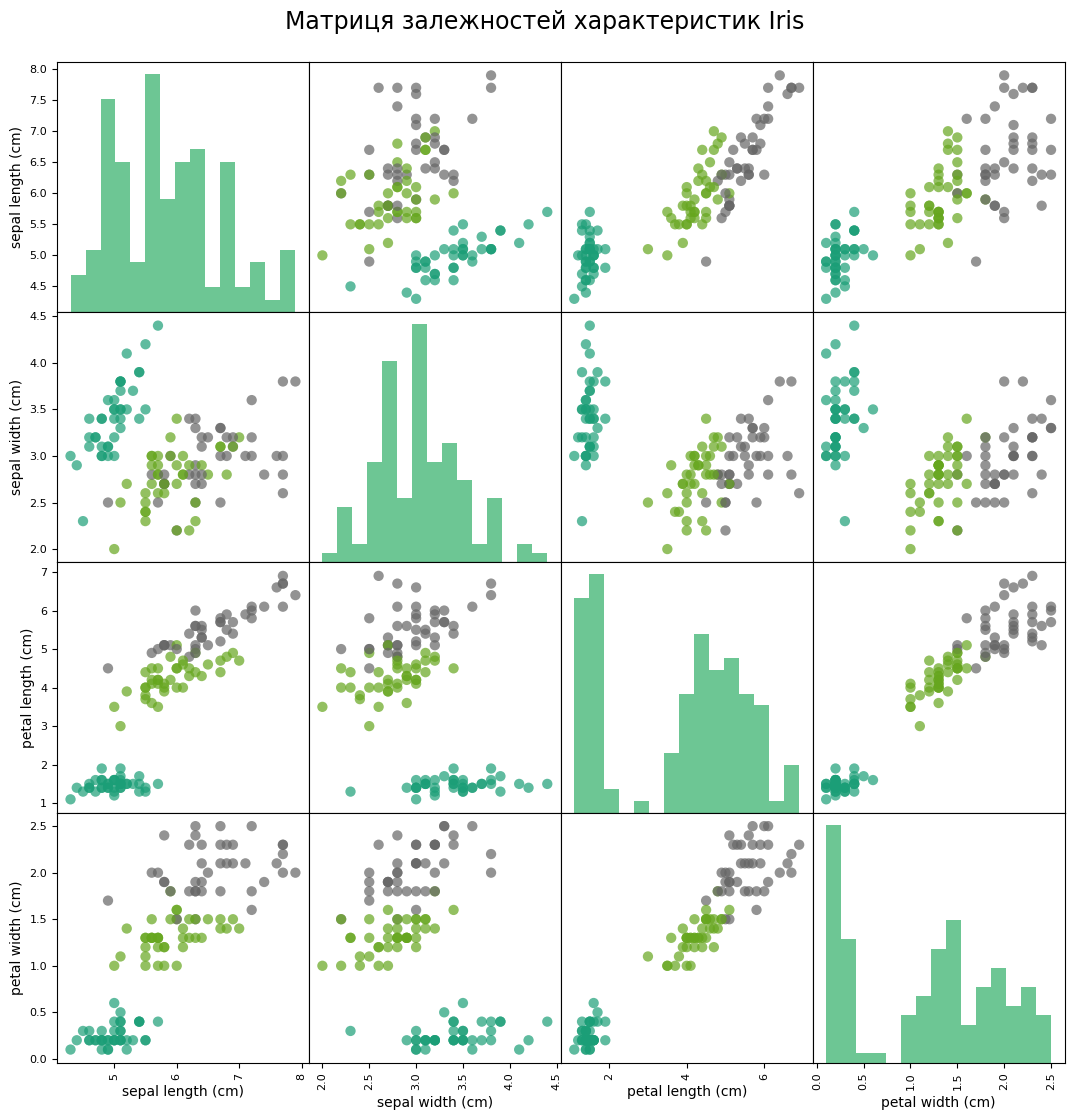

In [9]:
training_table = pd.DataFrame(
    train_features,
    columns=iris.feature_names
)

pd.plotting.scatter_matrix(
    training_table,
    c=train_labels,
    figsize=(13, 13),
    marker="o",
    s=55,
    alpha=0.70,
    cmap="Dark2",
    diagonal="hist",
    hist_kwds={
        "bins": 15,
        "color": "mediumseagreen",
        "alpha": 0.75
    },
    range_padding=0.12
)

plt.suptitle(
    "Матриця залежностей характеристик Iris",
    fontsize=17,
    y=0.92
)
plt.show()

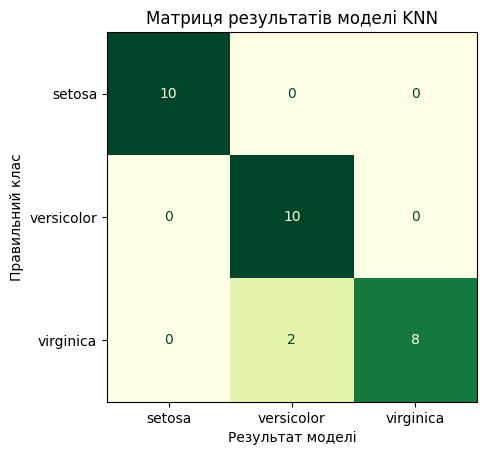

In [10]:
ConfusionMatrixDisplay.from_predictions(
    test_labels,
    predicted_labels,
    display_labels=iris.target_names,
    cmap="YlGn",
    values_format="d",
    colorbar=False
)

plt.title("Матриця результатів моделі KNN")
plt.xlabel("Результат моделі")
plt.ylabel("Правильний клас")
plt.show()

In [11]:
report = classification_report(
    test_labels,
    predicted_labels,
    target_names=iris.target_names,
    digits=3
)

print("Показники якості для кожного виду квітів")
print("=" * 48)
print(report)

Показники якості для кожного виду квітів
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

